In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

data = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print("Dataset loaded successfully!")
print(data.head())

Dataset loaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [ ]:
# Data Wrangling

print("Before cleaning:", data.shape)

data = data.dropna()
data = data.drop_duplicates()

print("After cleaning:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

Before cleaning: (5572, 2)
After cleaning: (5169, 2)

Missing values:
label      0
message    0
dtype: int64


In [ ]:
# Module 5: Separate Input and Output

X = data["message"]
y = data["label"]

print("Input data (X): Message")
print("Output data (y): Spam / Ham")
# Module 6: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Input data (X): Message
Output data (y): Spam / Ham
Training data: 4135
Testing data: 1034


In [ ]:
# Module 7: Text Feature Extraction

vectorizer = CountVectorizer()

# Convert training text into numerical features
X_train_vectorized = vectorizer.fit_transform(X_train)

# Convert testing text using the same vectorizer
X_test_vectorized = vectorizer.transform(X_test)

print("Text converted into numerical features!")
print("Training feature shape:", X_train_vectorized.shape)
print("Testing feature shape:", X_test_vectorized.shape)

Text converted into numerical features!
Training feature shape: (4135, 7585)
Testing feature shape: (1034, 7585)


In [ ]:
# Module 8: Model Training

model = MultinomialNB()

model.fit(X_train_vectorized, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Module 9: Model Evaluation

prediction = model.predict(X_test_vectorized)

accuracy = accuracy_score(y_test, prediction)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.16247582205028 %


Enter an email message: meet me at 2 pm

Message: meet me at 2 pm
Prediction: HAM


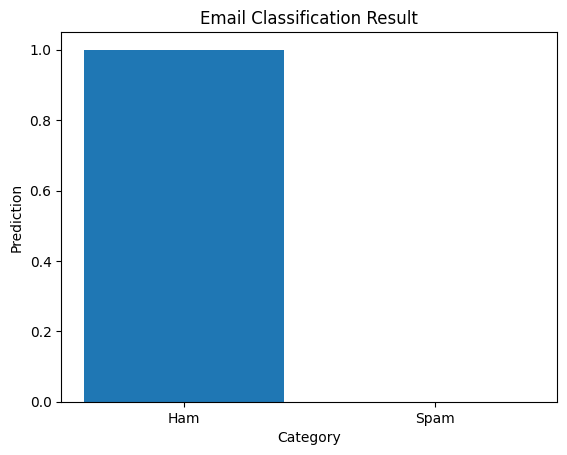

In [ ]:
import matplotlib.pyplot as plt
# Module 11: Manual Message Prediction

email = input("Enter an email message: ")

# Convert the new message into numerical features
email_vector = vectorizer.transform([email])

# Predict the category
result = model.predict(email_vector)[0]

print("\nMessage:", email)
print("Prediction:", result.upper())

if result == "spam":
    values = [0, 1]
else:
    values = [1, 0]

plt.bar(["Ham", "Spam"], values)

plt.title("Email Classification Result")
plt.xlabel("Category")
plt.ylabel("Prediction")

plt.show()

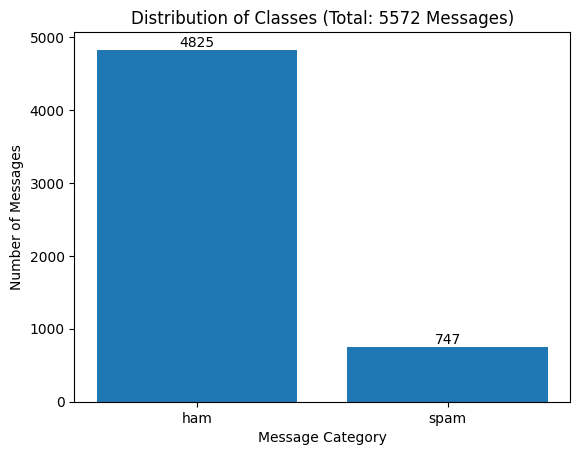

Ham messages: 4825
Spam messages: 747
Total messages: 5572


In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
data = pd.read_csv(url, sep="\t", header=None,
                   names=["label", "message"])

counts = data["label"].value_counts()
total = counts.sum()

bars = plt.bar(counts.index, counts.values)

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height(),
             int(bar.get_height()),
             ha="center", va="bottom")

plt.title(f"Distribution of Classes (Total: {total} Messages)")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.show()

print("Ham messages:", counts.get("ham", 0))
print("Spam messages:", counts.get("spam", 0))
print("Total messages:", total)



Training Accuracy: 99.33 %
Testing Accuracy: 99.19 %


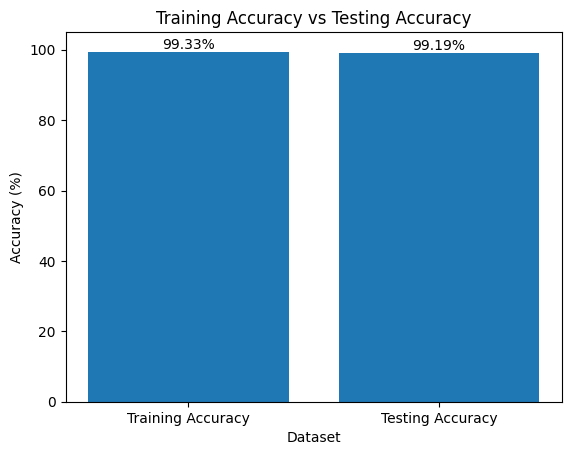

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Load dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
data = pd.read_csv(url, sep="\t", header=None,
                   names=["label", "message"])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    data["message"], data["label"],
    test_size=0.2, random_state=42
)

# Convert text into numbers
vectorizer = CountVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

# Train model
model = MultinomialNB()
model.fit(X_train_vectorized, y_train)

# Calculate accuracy
train_accuracy = accuracy_score(
    y_train, model.predict(X_train_vectorized)
) * 100

test_accuracy = accuracy_score(
    y_test, model.predict(X_test_vectorized)
) * 100

print("Training Accuracy:", round(train_accuracy, 2), "%")
print("Testing Accuracy:", round(test_accuracy, 2), "%")

# Display graph
labels = ["Training Accuracy", "Testing Accuracy"]
values = [train_accuracy, test_accuracy]

bars = plt.bar(labels, values)
plt.title("Training Accuracy vs Testing Accuracy")
plt.xlabel("Dataset")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center", va="bottom"
    )

plt.show()
